[← PT-08 GRPO from scratch](PT_08_grpo_from_scratch_toy_env.ipynb) | [↑ PostTraining](README.md) | [PT-10 GAE from scratch →](PT_10_gae_from_scratch_toy_env-CSharp.ipynb)

**Jumeau** · [Python](PT_09_rloo_from_scratch_toy_env.ipynb)
***

# PT-09 C# — RLOO (REINFORCE Leave-One-Out) from scratch : l'autre baseline sans critic

> **Place dans la série** : ce notebook suit `PT_08_grpo_from_scratch_toy_env.ipynb`  qui démontrait la mécanique du **group-relative advantage** de GRPO. PT-09 présente **RLOO** — *REINFORCE Leave-One-Out* — l'**autre** façon d'estimer une baseline **sans réseau value**. Ahmadian et al. l’étudient pour l’alignement des LLM, et Shao et al. introduisent GRPO dans DeepSeekMath. [Back to Basics (2024)](https://arxiv.org/abs/2402.14740) · [DeepSeekMath (2024)](https://arxiv.org/abs/2402.03300).

Les deux méthodes partagent la même idée-force — **remplacer le critic appris par une statistique tirée du groupe de complétions** — mais diffèrent sur la **forme de cette baseline** :

| Méthode | Baseline de la réponse $i$ | Échelle de l’avantage |
|---------|----------------------------|-----------------------|
| **GRPO** | $\bar r_g$, moyenne du groupe incluant $r_i$ | Division par $\sigma_g+\varepsilon$ |
| **RLOO** | $\bar r_{-i} = \frac{1}{G-1}\sum_{j\ne i}r_j$, moyenne des autres réponses | Différence brute $r_i-\bar r_{-i}$ |

RLOO est l'estimateur **leave-one-out** classique du contrôle de variance Monte Carlo : la baseline de la complétion $i$ est la moyenne des *autres* $G-1$ récompenses, donc $\mathbb{E}[\bar r_{-i}] = \mathbb{E}[r]$ exactement — l'avantage $r_i - \bar r_{-i}$ est un estimateur **non biaisé** de l'amélioration apportée par $i$.

## Objectifs d'apprentissage

1. **La baseline leave-one-out** : pourquoi exclure $r_i$ rend l'estimateur non biaisé, et pourquoi cela n'élimine pas la variance.
2. **RLOO vs GRPO** : deux baselines sans critic, un compromis biais-variance — mesuré sur un toy env.
3. **Le coût commun** : $G$ évaluations par prompt (le prix du « no critic »), et formuler une hypothèse sur la sensibilité à la taille du groupe.

## Prérequis

`PT_08`  (GRPO, group-relative advantage) — ce carnet reprend l’équation du banc de PT-08, avec huit actions et un MLP propre à cette expérience.

**Prérequis C#** · .NET Interactive, TorchSharp CPU, Z3 4.12.2. La configuration Linux figure dans le README.
**Durée pédagogique** · 45 min.

## Installation et configuration

On retrouve la contrainte de PT-08, $s^2+a=b$, avec $0\le a\le5$ et huit actions $s\in\{0,\ldots,7\}$. Le nombre d’actions et l’encodage peuvent différer de PT-08. Le test attribue une récompense binaire à la racine entière correcte. Z3 vérifie le prédicat et l’entraînement exploite son équivalent vectorisé.

Le MLP de 1 416 paramètres est un acteur seul. TorchSharp utilise le moteur libtorch sur CPU. Configurez la bibliothèque native Z3 depuis le README avant d’ouvrir le noyau.

In [1]:
#r "nuget: TorchSharp-cpu, 0.107.0"
#r "nuget: Microsoft.Z3, 4.12.2"
using System;
using System.Collections.Generic;
using System.Globalization;
using System.IO;
using System.Linq;
using System.Runtime.InteropServices;
using System.Text;
using TorchSharp;
using static TorchSharp.torch;
using Microsoft.DotNet.Interactive.Formatting;
using Z3 = Microsoft.Z3;

// Le moteur managé et la bibliothèque Z3 native doivent correspondre sur Linux.
if (RuntimeInformation.IsOSPlatform(OSPlatform.Linux))
{
    string cheminZ3 = Environment.GetEnvironmentVariable("Z3_NATIVE_LIBRARY");
    if (string.IsNullOrWhiteSpace(cheminZ3) || !File.Exists(cheminZ3))
        throw new InvalidOperationException("Configurer Z3_NATIVE_LIBRARY avant de lancer le noyau (voir README).");
    NativeLibrary.SetDllImportResolver(typeof(Z3.Context).Assembly,
        (nom, assembly, recherche) => nom == "libz3" ? NativeLibrary.Load(cheminZ3) : IntPtr.Zero);
}
torch.set_num_threads(1);
torch.manual_seed(42);
Console.WriteLine($".NET {Environment.Version}, TorchSharp CPU 0.107.0, threads={torch.get_num_threads()}, Z3 {Z3.Version.FullVersion}, graine 42.");

Installed Packages Microsoft.Z3, 4.12.2 TorchSharp-cpu, 0.107.0

Loading extensions from `/workspace/coursia-toolchains/nuget/skiasharp/2.88.6/interactive-extensions/dotnet/SkiaSharp.DotNet.Interactive.dll`

.NET 10.0.14, TorchSharp CPU 0.107.0, threads=1, Z3 Z3 4.12.2.0, graine 42.


La sortie indique le runtime choisi, le nombre de threads et la version du solveur natif.

In [2]:
const int MaxA = 5, Actions = 8, MaxB = (Actions - 1) * (Actions - 1) + MaxA;
const int Invites = 32, Semence = 42;
const double Taux = 5e-3;
var contexte = new Z3.Context();
var solutionZ3 = contexte.MkIntConst("s");
var solveur = contexte.MkSolver();
bool VerifierZ3(int a, int b, int s)
{
    // Push/Pop isolent la contrainte de chaque réponse tout en réutilisant le moteur.
    using var termeA = contexte.MkInt(a);
    using var termeB = contexte.MkInt(b);
    using var termeS = contexte.MkInt(s);
    using var borneInferieure = contexte.MkInt(0);
    using var borneSuperieure = contexte.MkInt(Actions);
    using var carre = contexte.MkMul(solutionZ3, solutionZ3);
    using var somme = contexte.MkAdd(carre, termeA);
    using var egalite = contexte.MkEq(somme, termeB);
    using var min = contexte.MkGe(solutionZ3, borneInferieure);
    using var max = contexte.MkLt(solutionZ3, borneSuperieure);
    using var fixation = contexte.MkEq(solutionZ3, termeS);
    solveur.Push();
    try
    {
        solveur.Add(egalite, min, max, fixation);
        return solveur.Check() == Z3.Status.SATISFIABLE;
    }
    finally
    {
        solveur.Pop();
    }
}
bool Predicat(int a, int b, int s) => s >= 0 && s < Actions && s * s + a == b;
Tensor Recompense(Tensor a, Tensor b, Tensor s) =>
    ((s * s + a).eq(b).logical_and(s.ge(0)).logical_and(s.lt(Actions))).to_type(ScalarType.Float32);

(long[] A, long[] B) Lot(Random alea, int invites, int repetitions = 1)
{
    var a = new long[invites * repetitions];
    var b = new long[invites * repetitions];
    for (int i = 0; i < invites; i++)
    {
        int decalage = alea.Next(MaxA + 1), racine = alea.Next(Actions);
        // La racine est cachée. On duplique la même invite pour ses réponses indépendantes.
        Array.Fill(a, decalage, i * repetitions, repetitions);
        Array.Fill(b, racine * racine + decalage, i * repetitions, repetitions);
    }
    return (a, b);
}
Tensor LogProbasChoisies(Tensor logProbas, Tensor actions) =>
    logProbas.gather(1, actions.unsqueeze(1)).squeeze(1);
Tensor Tirer(Tensor logProbas) => logProbas.exp().multinomial(1).squeeze(1);

var aleaPreuve = new Random(Semence);
var preuves = new List<(int A, int B, int S)>();
// Les 384 triplets valides de ce domaine sont testés exhaustivement.
for (int a = 0; a <= MaxA; a++)
    for (int r = 0; r < Actions; r++)
        for (int s = 0; s < Actions; s++)
            preuves.Add((a, r * r + a, s));
// Les cas frontières comportent aussi des faux candidats, des b inatteignables et des réponses hors domaine.
while (preuves.Count < 2400)
    preuves.Add((aleaPreuve.Next(MaxA + 1), aleaPreuve.Next(-5, MaxB + 6), aleaPreuve.Next(-2, Actions + 3)));
using (var preuve = torch.NewDisposeScope())
{
    var attendu = preuves.Select(p => VerifierZ3(p.A, p.B, p.S) ? 1f : 0f).ToArray();
    var a = torch.tensor(preuves.Select(p => (long)p.A).ToArray());
    var b = torch.tensor(preuves.Select(p => (long)p.B).ToArray());
    var s = torch.tensor(preuves.Select(p => (long)p.S).ToArray());
    var vecteur = Recompense(a, b, s).data<float>().ToArray();
    int ecarts = vecteur.Zip(attendu).Count(p => p.First != p.Second);
    int ecartsScaler = preuves.Select((p, i) => Predicat(p.A, p.B, p.S) == (attendu[i] == 1)).Count(ok => !ok);
    if (ecarts != 0 || ecartsScaler != 0)
        throw new InvalidOperationException("Divergence entre la récompense de l'entraînement et le SMT.");
    Console.WriteLine($"Z3 et récompense tensorielle : {preuves.Count} vérifications, {ecarts} divergence côté tenseurs, {ecartsScaler} côté scalaire.");
}
var exemples = Lot(new Random(100), 4);
foreach (var (a, b) in exemples.A.Zip(exemples.B))
{
    var racines = Enumerable.Range(0, Actions).Where(s => VerifierZ3((int)a, (int)b, s));
    Console.WriteLine($"(a={a}, b={b}) → solutions Z3 [{string.Join(", ", racines)}].");
}
var aleaActions = new Random(2);
var aleaInvites = Lot(new Random(0), 4000);
int succesHasard = aleaInvites.A.Zip(aleaInvites.B)
    .Count(p => Predicat((int)p.First, (int)p.Second, aleaActions.Next(Actions)));
Console.WriteLine($"Hasard : {succesHasard}/4000 = {succesHasard / 4000.0:F3}, référence 1/{Actions} = {1.0 / Actions:F3}.");

Z3 et récompense tensorielle : 2400 vérifications, 0 divergence côté tenseurs, 0 côté scalaire.


(a=5, b=6) → solutions Z3 [1].


(a=4, b=53) → solutions Z3 [7].


(a=2, b=51) → solutions Z3 [7].


(a=4, b=20) → solutions Z3 [4].


Hasard : 518/4000 = 0.130, référence 1/8 = 0.125.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply r

Les quatre requêtes illustrent les racines attendues. La comparaison vérifie le prédicat scalaire et le tenseur de récompenses face au solveur.

### Le témoin uniforme et les cas de bord

Sur ce domaine fini, il existe une seule réponse correcte par invite. Une politique uniforme a donc une espérance $1/8$. Les 4 000 tirages donnent une estimation de ce niveau. Entraîner une politique qui le dépasse indique un apprentissage sur ce banc, sans établir de généralisation hors du domaine.

In [3]:
// Les deux entrées sont les scalaires a et b ; la dernière couche a un logit par racine possible.
const int TailleGroupe = 8, Episodes = 400, EpoquesPpo = 4;
const double EpsilonGroupe = 1e-4;
torch.nn.Module<Tensor, Tensor> Acteur() => nn.Sequential(nn.Linear(2, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, Actions));
var controleArchitecture = Acteur();
long nombreActeur = controleArchitecture.parameters().Sum(p => p.numel());
controleArchitecture.Dispose();
if (nombreActeur != 1416)
    throw new InvalidOperationException("Architecture de l'acteur inattendue.");
Console.WriteLine($"MLP 2→32→32→{Actions}, {nombreActeur} paramètres, aucun critic. Groupe {TailleGroupe} et {EpoquesPpo} mises à jour sur un groupe.");

MLP 2→32→32→8, 1416 paramètres, aucun critic. Groupe 8 et 4 mises à jour sur un groupe.


La politique MLP (Multi-Layer Perceptron) créée from-scratch compte 1416 paramètres. Cette architecture simple d'acteur est suffisante pour le toy-env, et est volontairement dépourvue de critique (critic), car ni RLOO ni GRPO n'en nécessitent un.

### Interprétation : pas de critic

RLOO et GRPO tirent leur baseline des récompenses du groupe. Le §3 compare le budget d’acteur avec celui d’un critic hypothétique construit en remplaçant la sortie à huit logits par une sortie scalaire. Le compte porte sur cette architecture.

PT-08 entraîne un critic réel sur un autre banc quadratique, avec seize actions et un encodage différent. La figure et la table du présent carnet décrivent le MLP à huit actions.

## 1. La baseline leave-one-out (RLOO)

Pour un prompt donné, on tire $G$ complétions de la policy, on observe leurs récompenses $r_1, \dots, r_G$. La **baseline leave-one-out** pour la complétion $i$ est :

$$\bar r_{-i} = \frac{1}{G-1} \sum_{j \ne i} r_j$$

L'avantage RLOO est $A_i^{\text{RLOO}} = r_i - \bar r_{-i}$. Deux propriétés :

- **Non biaisé** : $\mathbb{E}[\bar r_{-i}] = \mathbb{E}[r]$ (la complétion $i$ est exclue, donc la baseline est une estimation honnête de la performance moyenne attendue). Le gradient RLOO est un estimateur non biaisé du gradient de la policy.
- **Variance** : la baseline dépend des $G-1$ *autres* échantillons, donc elle fluctue. Quand $G$ est petit, $\bar r_{-i}$ est bruitée. C'est le coût de l'absence de critic (la qualité d’un critic appris peut modifier la variance, au prix de ses propres paramètres et d’une optimisation supplémentaire).

À comparer avec GRPO : $A_i^{\text{GRPO}} = (r_i - \bar r_g) / (\sigma_g + \varepsilon)$, où $\bar r_g$ **inclut** $r_i$ et la normalisation par $\sigma_g+\varepsilon$ change l’échelle des avantages. L’effet sur le gradient dépend de la distribution des récompenses.

In [4]:
Tensor AvantageRloo(Tensor recompenses, int g) =>
    recompenses - (recompenses.sum(new long[] {1}, keepdim: true) - recompenses) / (g - 1);
Tensor AvantageGrpo(Tensor recompenses)
{
    var moyenne = recompenses.mean(new long[] {1}, keepdim: true);
    // Correction d'échantillon à 1, comme torch.std dans le carnet Python.
    var dispersion = recompenses.std(new long[] {1}, unbiased: true, keepdim: true);
    return (recompenses - moyenne) / (dispersion + EpsilonGroupe);
}
double[] EntrainementGroupe(string methode, Func<Tensor, int, Tensor> avantage, int g = TailleGroupe,
    int episodes = Episodes, int seed = Semence)
{
    if (g < 2) throw new ArgumentOutOfRangeException(nameof(g), "Deux réponses au moins.");
    torch.manual_seed(seed);
    var alea = new Random(seed);
    using var acteur = Acteur();
    using var adam = torch.optim.Adam(acteur.parameters(), lr: Taux);
    var historique = new double[episodes];
    for (int it = 0; it < episodes; it++)
    {
        using var episode = torch.NewDisposeScope();
        var (a, b) = Lot(alea, Invites, g);
        var at = torch.tensor(a);
        var bt = torch.tensor(b);
        var entrees = torch.stack(new[] {at.to_type(ScalarType.Float32), bt.to_type(ScalarType.Float32)}, 1);
        Tensor actions, logpAvant, r, adv;
        // Les anciennes log-probabilités sont figées pendant les quatre passes du groupe.
        using (torch.no_grad())
        {
            var logp = acteur.forward(entrees).log_softmax(1);
            actions = Tirer(logp);
            logpAvant = LogProbasChoisies(logp, actions).reshape(Invites, g);
            r = Recompense(at, bt, actions).reshape(Invites, g);
            adv = avantage(r, g);
        }
        for (int epoque = 0; epoque < EpoquesPpo; epoque++)
        {
            using var passe = torch.NewDisposeScope();
            var logp = acteur.forward(entrees).log_softmax(1);
            var courant = LogProbasChoisies(logp, actions).reshape(Invites, g);
            // La référence est le ratio d'importance sans clipping de ce banc, pour les deux méthodes.
            var ratio = (courant - logpAvant).exp();
            var perte = -(ratio * adv).mean();
            adam.zero_grad();
            perte.backward();
            adam.step();
        }
        historique[it] = r.mean().item<float>();
    }
    if (historique.Any(x => !double.IsFinite(x)))
        throw new InvalidOperationException($"Récompenses non finies pour {methode}.");
    return historique;
}
double[] EntrainerRloo(int g = TailleGroupe, Func<Tensor, int, Tensor> avantage = null) =>
    EntrainementGroupe("RLOO", avantage ?? AvantageRloo, g);
using (var fixture = torch.NewDisposeScope())
{
    // Avec deux réponses, l'avantage de l'une est la différence avec l'autre.
    var r = torch.tensor(new float[] {1, 0, 1, 1}).reshape(2, 2);
    var a = AvantageRloo(r, 2).data<float>().ToArray();
    if (!a.SequenceEqual(new float[] {1, -1, 0, 0}))
        throw new InvalidOperationException("La baseline ne retire pas seulement la récompense de l'autre.");
    Console.WriteLine($"Témoin RLOO G=2 : {string.Join(", ", a)}. Une moyenne constante donne un avantage nul.");
}

Témoin RLOO G=2 : 1, -1, 0, 0. Une moyenne constante donne un avantage nul.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply r

RLOO (Reinforcement Learning with Leave-One-Out) est défini avec une baseline leave-one-out produisant un avantage non biaisé. La configuration utilise K=4 époques de réutilisation du groupe via un **ratio d'importance** (sans clipping : l'objectif PPO tronqué n'est pas utilisé), offrant un bon compromis entre stabilité de l'apprentissage et coût computationnel pour ce toy-problem.

## 2. Comparaison RLOO vs GRPO (même toy env, même seed)

On ré-entraîne **GRPO** (baseline = moyenne du groupe normalisée) et **REINFORCE** (baseline = moyenne du batch) sur le même toy env, avec la même seed et le même nombre d'épisodes. **Attention : les budgets d'updates ne sont pas égaux** — RLOO et GRPO réutilisent chaque groupe pendant `PPO_EPOCHS = 4` mises à jour par épisode, quand REINFORCE n'en fait qu'**une seule** (et n'échantillonne qu'une complétion par prompt). L'écart mesuré entre les courbes mêle donc l'effet du choix de baseline et l'effet de ce budget d'updates inégal ; la section 3 détaille la structure de coûts par méthode.

In [5]:
double[] EntrainerGrpo(int g = TailleGroupe) => EntrainementGroupe("GRPO", (r, _) => AvantageGrpo(r), g);
double[] EntrainerReinforce()
{
    torch.manual_seed(Semence);
    var alea = new Random(Semence);
    using var modele = Acteur();
    using var adam = torch.optim.Adam(modele.parameters(), lr: Taux);
    var historique = new double[Episodes];
    for (int it = 0; it < Episodes; it++)
    {
        using var episode = torch.NewDisposeScope();
        var (a, b) = Lot(alea, Invites);
        var at = torch.tensor(a);
        var bt = torch.tensor(b);
        var x = torch.stack(new[] {at.to_type(ScalarType.Float32), bt.to_type(ScalarType.Float32)}, 1);
        var logp = modele.forward(x).log_softmax(1);
        var actions = Tirer(logp);
        var r = Recompense(at, bt, actions);
        // Une seule réponse par invite, et une baseline commune à tout le lot.
        var adv = r - r.mean();
        var perte = -(LogProbasChoisies(logp, actions) * adv).mean();
        adam.zero_grad();
        perte.backward();
        adam.step();
        historique[it] = r.mean().item<float>();
    }
    return historique;
}
using (var fixture = torch.NewDisposeScope())
{
    var groupes = torch.tensor(new float[] {1, 0, 0, 0, 1, 1, 1, 1}).reshape(2, 4);
    var adv = AvantageGrpo(groupes).data<float>().ToArray();
    if (!(adv[0] > 0 && adv[1] < 0 && adv.Skip(4).All(x => x == 0)))
        throw new InvalidOperationException("La normalisation des groupes échoue sur le témoin.");
    Console.WriteLine($"GRPO : avantage positif {adv[0]:F3}, négatif {adv[1]:F3}, groupe constant nul.");
}

GRPO : avantage positif 1.500, négatif -0.500, groupe constant nul.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply r

GRPO (Group Relative Policy Optimization) est configuré avec une baseline calculée comme la moyenne du groupe, normalisée par l'écart-type. Cette approche, rappelée de PT-08, permet une estimation robuste de l'avantage pour la mise à jour de la politique.

In [6]:
// Trois optimisations réelles, avec la même graine nominale et leur budget d'actions propre.
var hReinforce = EntrainerReinforce();
var hRloo = EntrainerRloo();
var hGrpo = EntrainerGrpo();
Console.WriteLine($"{"Méthode",-13} {"Baseline",-19} {"Début",7} {"Fin",7} {"Maximum",8}");
foreach (var (nom, baseline, h) in new[] { ("REINFORCE", "moyenne du lot", hReinforce),
    ("RLOO", "leave-one-out", hRloo), ("GRPO", "groupe normalisé", hGrpo) })
    Console.WriteLine($"{nom,-13} {baseline,-19} {h[0],7:F3} {h[^1],7:F3} {h.Max(),8:F3}");

Méthode       Baseline              Début     Fin  Maximum


REINFORCE     moyenne du lot        0.062   0.719    0.875


RLOO          leave-one-out         0.117   0.375    0.875


GRPO          groupe normalisé      0.117   0.562    0.871


La sortie distingue début, fin et maximum. Ces trois statistiques n’ont pas la même signification : le maximum est une valeur rencontrée pendant l’optimisation. Le budget de données et de mises à jour diffère entre méthodes.

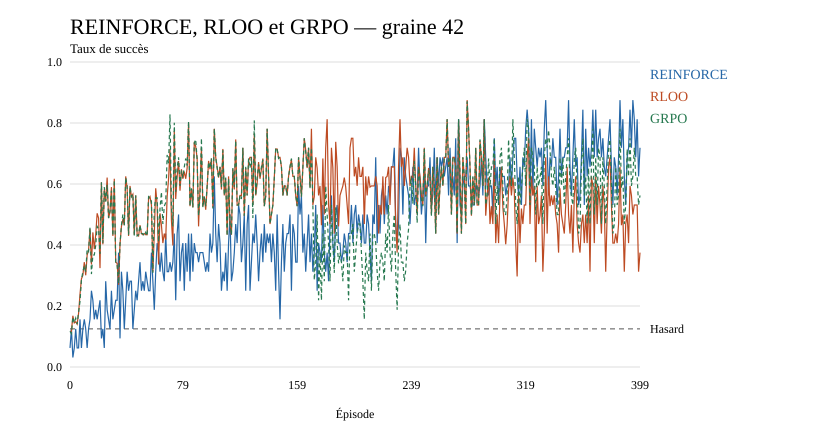

In [7]:
record CourbesSvg(string Contenu);
Formatter.Register<CourbesSvg>((courbes, writer) => writer.Write(courbes.Contenu), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(CourbesSvg), "image/svg+xml");
string Dessin(FormattableString texte) => texte.ToString(CultureInfo.InvariantCulture);
string Echapper(string texte) => System.Net.WebUtility.HtmlEncode(texte);
double EcartType(IReadOnlyCollection<double> valeurs)
{
    double m = valeurs.Average();
    return Math.Sqrt(valeurs.Average(x => (x - m) * (x - m)));
}
void Tracer(
    string titre, string abscisse, (string Nom, string Couleur, double[] Moyenne, double[] Dispersion)[] series,
    double? hasard = null)
{
    const int largeur = 820, hauteur = 440;
    int n = series[0].Moyenne.Length;
    double X(int t) => 70 + 570.0 * t / (n - 1);
    double Y(double r) => 367 - 305 * Math.Clamp(r, 0, 1);
    string Points(IReadOnlyList<double> serie) =>
        string.Join(" ", serie.Select((valeur, t) => Dessin($"{X(t):F2},{Y(valeur):F2}")));
    var svg = new StringBuilder(Dessin($"<svg xmlns='http://www.w3.org/2000/svg' width='{largeur}' height='{hauteur}' viewBox='0 0 {largeur} {hauteur}' role='img'><title>{Echapper(titre)}</title><rect width='100%' height='100%' fill='white'/>"));
    svg.Append(Dessin($"<text x='70' y='34' font-size='22'>{Echapper(titre)}</text><text x='70' y='53' font-size='13'>Taux de succès</text>"));
    for (int i = 0; i <= 5; i++)
    {
        double r = i / 5.0;
        svg.Append(Dessin($"<path d='M70 {Y(r):F2} H640' stroke='#DDD'/><text x='62' y='{Y(r)+4:F2}' text-anchor='end'>{r:F1}</text>"));
        int t = i * (n - 1) / 5;
        svg.Append(Dessin($"<text x='{X(t):F2}' y='389' text-anchor='middle'>{t}</text>"));
    }
    svg.Append(Dessin($"<text x='355' y='418' text-anchor='middle'>{Echapper(abscisse)}</text>"));
    if (hasard.HasValue)
        svg.Append(Dessin($"<path d='M70 {Y(hasard.Value):F2} H640' stroke='#555' stroke-dasharray='5 4'/><text x='650' y='{Y(hasard.Value)+4:F2}'>Hasard</text>"));
    for (int j = 0; j < series.Length; j++)
    {
        var s = series[j];
        // Bande ± écart type autour de la trajectoire multi-graines, quand une dispersion est mesurée.
        if (s.Dispersion.Length != 0)
        {
            var haut = s.Moyenne.Zip(s.Dispersion).Select(p => p.First + p.Second).ToArray();
            var bas = s.Moyenne.Zip(s.Dispersion).Select(p => p.First - p.Second).ToArray();
            string retour = string.Join(" ", bas.Select((v, i) => Dessin($"{X(i):F2},{Y(v):F2}")).Reverse());
            svg.Append(Dessin($"<polygon points='{Points(haut)} {retour}' fill='{s.Couleur}' fill-opacity='0.13'/>"));
        }
        string tirets = j == 2 ? " stroke-dasharray='4 3'" : "";
        svg.Append(Dessin($"<polyline points='{Points(s.Moyenne)}' fill='none' stroke='{s.Couleur}' stroke-width='1.2'{tirets}/>"));
        svg.Append(Dessin($"<text x='650' y='{79 + 22*j}' fill='{s.Couleur}' font-size='14'>{Echapper(s.Nom)}</text>"));
    }
    display(new CourbesSvg(svg.Append("</svg>").ToString()));
}

// Toutes les récompenses sont tracées, avec la probabilité structurale de référence.
var courbes = new[] { ("REINFORCE", "#2667a7", hReinforce, Array.Empty<double>()),
    ("RLOO", "#bd4b23", hRloo, Array.Empty<double>()), ("GRPO", "#277950", hGrpo, Array.Empty<double>()) };
Tracer("REINFORCE, RLOO et GRPO — graine 42", "Épisode", courbes, 1.0 / Actions);

Le graphe trace les 400 récompenses avec leur variabilité d’un épisode à l’autre. La ligne de hasard situe le repère uniforme.

### Interprétation : le compromis biais-variance

Conditionnellement à l’invite, RLOO retire la moyenne des autres réponses. Modifier la récompense courante ne change donc pas cette baseline. Avec un petit groupe, la moyenne des autres réponses peut fluctuer davantage.

GRPO centre sur une moyenne qui inclut la réponse courante puis divise par l’écart-type empirique du groupe. La baseline du lot REINFORCE inclut elle aussi l’échantillon courant. Le centrage agit déjà sur l’échelle du gradient, et la normalisation modifie sa sensibilité aux récompenses atypiques. Une trajectoire issue d’une graine ne prouve pas que la normalisation réduit toujours la variance.

La lecture conjointe des colonnes début, fin et maximum et des courbes indique les compromis observés. Isoler la baseline demanderait une ablation à budgets d’échantillons et de mises à jour égaux.

### Exercice 1 — Mesurer l’effet de la taille du groupe

Relancer les deux avantages avec G=4, 8 et 16. Utiliser 200 épisodes par essai via le paramètre episodes de la boucle commune. Garder les autres réglages et noter séparément le nombre de réponses. À petit G, mesurer les fluctuations de la moyenne des autres récompenses et l’effet du centrage-réduction, puis comparer les résultats.

In [8]:
// TODO : entraîner sur g = 4, 8 et 16, puis comparer les deux méthodes sur la taille de groupe.
var tailles = new[] {4, 8, 16};
Dictionary<int, (double Rloo, double Grpo)> comparaisonG = null;
Console.WriteLine("Exercice 1 à compléter : comparer les récompenses finales selon G.");

Exercice 1 à compléter : comparer les récompenses finales selon G.


## 3. Budget : le coût commun du « no critic »

GRPO et RLOO paient **$G$ échantillonnages par prompt** (ici $G=8$), contre 1 pour REINFORCE, et $G + K\!\times\!G$ pour PPO (groupe + ré-utilisation multi-epochs). Comptant les **passes forward du ratio d'importance**, les trois méthodes à ré-émission paient le même coût : $G(1+K)$ forward par prompt — les $K$ passes de gradient recalculent le logp des mêmes $G$ complétions. Sur ce toy, c'est négligeable ; sur un LLM, c'est le coût dominant du post-training.

| Méthode | Baseline | Critic | Forward/prompt | Params réseau (ce toy) |
|---------|----------|--------|----------------|------------------------|
| REINFORCE | moyenne batch | non | 1 | **1 416** (acteur seul) |
| **RLOO** | leave-one-out | **non** | $G(1+K) = 40$ | **1 416** (acteur seul) |
| **GRPO** | groupe normalisé | **non** | $G(1+K) = 40$ | **1 416** (acteur seul) |
| PPO *hypothétique* (même toy) | critic appris | oui | $G(1+K) = 40$ + critic | **2 601** = 1 416 acteur + **1 185 critic dérivé** (§ 3) |
| PPO *entraîné dans PT-08* (autre banc, 16 actions) | critic appris | oui | $G(1+K)$ + critic | 31 569 = 16 272 acteur + 15 297 critic (encodeur distinct, voir PT-08) |

La colonne « Forward/prompt » ne distingue donc **pas** RLOO/GRPO de PPO : l'économie « no critic » est dans le **réseau** (colonne de droite), pas dans les forward d'échantillons.

Sur ce notebook, l'écart « no critic » **dérivé** de l'acteur est donc **~46 %** de paramètres (`1185 / (1416 + 1185) = 0.4555`). C'est la **mesure locale** au toy env quadratique. Ce rapport dépend de l’architecture et ne s’étend pas automatiquement à un LLM. La « projection 1 185 » n'est **pas** un critic PT-08 — c'est un miroir arithmétique de l'acteur de **ce** notebook avec une tête value scalaire.


In [9]:
// Critic hypothétique de même architecture que l'acteur, avec une seule sortie.
int critic = 2 * 32 + 32 + 32 * 32 + 32 + 32 + 1;
Console.WriteLine($"Acteur : {nombreActeur} paramètres. Critic hypothétique : {critic} paramètres.");
Console.WriteLine($"Part évitée sans critic : {100.0 * critic / (nombreActeur + critic):F0} % de la somme acteur-critic.");
Console.WriteLine($"RLOO/GRPO : {TailleGroupe} évaluations par invite et {EpoquesPpo} mises à jour au lieu de 1 pour REINFORCE.");

Acteur : 1416 paramètres. Critic hypothétique : 1185 paramètres.


Part évitée sans critic : 46 % de la somme acteur-critic.


RLOO/GRPO : 8 évaluations par invite et 4 mises à jour au lieu de 1 pour REINFORCE.


L'analyse du budget paramétrique révèle que l'acteur (policy) compte 1416 paramètres. L'économie de RLOO et GRPO par rapport à une approche type PPO avec critique est estimée à environ 1185 paramètres (46% de réduction), au prix d'un surcoût de 7 évaluations par prompt par rapport à REINFORCE (avec G=8). Ce trade-off illustre le compromis classique entre complexité du modèle et coût computationnel.

### Exercice 2 : baseline médiane (robustesse aux valeurs extrêmes)
Étape 1 : remplacez la baseline leave-one-out (moyenne) par la MÉDIANE leave-one-out.
Indice : Tensor.median sur les G-1 autres récompenses. La médiane est robuste aux outliers.
Question : sur un reward binaire (0/1), médiane et moyenne laissent-elles passer un signal quand G est pair ?


In [10]:
// TODO : prendre la médiane des autres récompenses avant de soustraire la baseline.
Func<Tensor, int, Tensor> avantageMedian = null;
double[] courbeMediane = null;
Console.WriteLine("Exercice 2 à compléter : tester une baseline médiane et comparer sa sensibilité.");

Exercice 2 à compléter : tester une baseline médiane et comparer sa sensibilité.


## 4. Étudier les estimateurs

Les exercices font varier la taille du groupe, sa statistique de référence et le centrage-réduction.

### Exercice 3 — Comparer les avantages et leur variance à G=2

Pour des groupes de deux réponses, calculer l’avantage RLOO et l’avantage GRPO à partir des mêmes récompenses. Vérifier le signe des deux résultats et comparer leurs amplitudes pour une différence faible puis forte. Étudier leur variance sur plusieurs groupes et expliquer l’effet de la normalisation.

In [11]:
// TODO : sous G=2, comparer la différence des récompenses au centrage-réduction du groupe.
Dictionary<string, double> comparaisonG2 = null;
Console.WriteLine("Exercice 3 à compléter : expliciter les deux avantages et étudier leur variance.");

Exercice 3 à compléter : expliciter les deux avantages et étudier leur variance.


## 5. Verdict et transfert toy -> LLM

La comparaison invoque Z3, entraîne trois politiques TorchSharp en CPU et mesure un témoin uniforme. Les trajectoires caractérisent cette réalisation du banc, pour une graine nominale.

**Transfert toy -> LLM** (ce qui change à l'échelle d'un Qwen3.5-0.8B) :
- **L'avantage** est inchangé : $r_i - \bar r_{-i}$ (RLOO) ou $(r_i - \bar r_g)/\sigma_g$ (GRPO), calculé sur $G$ complétions du même prompt.
- **Le logp** devient le log-probabilité **token par token** d'une séquence autoregressive (somme sur les tokens), pas le logp d'une action discrète unique.
- **La KL** : on ajoute une pénalité $\beta \cdot \mathrm{KL}(\pi_\theta \| \pi_{\text{ref}})$ vers la policy de référence (SFT) pour éviter que le RL ne dégrade le langage — c'est la différence clé avec ce toy (où aucune KL n'est nécessaire).
- **Le coût** : $G$ forward-pass d'un LLM par prompt (des milliers de tokens chacune), d'où l'importance du choix de $G$ (Deepseek: $G=4$ à $64$ selon le régime).

**Pourquoi RLOO existe à côté de GRPO** : ce notebook montre que « non biaisé » (RLOO) ne bat pas « normalisé » (GRPO) sur ce toy — mais à **petit $G$**, le biais de GRPO (inclusion de $r_i$) devient non négligeable, et l'estimateur non biaisé de RLOO redevient attrayant. C'est un compromis empirique, pas un gagnant universel.

**Les étages réels de ce transfert existent dans la série** : `PT_04_grpo_deepseek_r1.ipynb` implémente le vrai entraîneur (`from trl import GRPOTrainer, GRPOConfig` ; `num_generations: 4` — le même rôle que le $G$ de ce toy, groupe de complétions par prompt, à une valeur moindre : $G=8$ en toy, $G=4$ à l'étage réel, conformément au compromis coût ci-dessus ; run de démonstration borné à `max_steps: 3`), et `PT_11a_grpo_qwen35_rlvr.ipynb` **l'exécute réellement** sur Qwen3.5-0.8B + QLoRA 4-bit avec la même arithmétique Z3 que ce toy : 800 récompenses enregistrées, moyenne globale **0.1263**, max **1.0000**, 540 672 paramètres entraînables sur 752 933 696. Le toy (1 416 paramètres) et le réel (0.8 Md) optimisent le même objet mathématique : un avantage de groupe estimé sans critic.

## Conclusion

Le solveur établit la récompense binaire du banc et le témoin uniforme permet de situer l’apprentissage observé.

RLOO estime la baseline sans la réponse évaluée. GRPO centre et normalise les réponses du groupe. L’absence de critic économise des paramètres, tandis qu’un groupe augmente le nombre de réponses et que sa réutilisation augmente le nombre de mises à jour. Ces quantités mesurent le banc et n’établissent pas le coût d’un LLM.

## Pour aller plus loin — le même entraînement sans critic, sur le vrai LLM

**Étape suivante** — [PT-04 — GRPO avec `trl`, à la main](PT_04_grpo_deepseek_r1.ipynb) : le vrai `trl.GRPOTrainer` (`num_generations: 4` : le $G$ de ce toy dans son rôle de groupe de complétions par prompt, passé de $8$ en toy à $4$ à l'échelle ; run borné à 3 steps), cellule par cellule. Puis [PT-11a — GRPO réel sur Qwen3.5-0.8B](PT_11a_grpo_qwen35_rlvr.ipynb) : la boucle complète **exécutée** — QLoRA 4-bit, reward Z3, 800 récompenses (moyenne globale 0.1263, max 1.0000). Pour la voie avec critic que ce notebook a tenue à distance : [PT-10 — GAE](PT_10_gae_from_scratch_toy_env-CSharp.ipynb) ; pour la baseline empirique jumelle : [PT-08 — GRPO from scratch](PT_08_grpo_from_scratch_toy_env.ipynb).